In [ ]:
import random
import shutil
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from matplotlib import patches
from PIL import Image
from ultralytics import YOLO

torch.set_float32_matmul_precision("high")

print(f"PyTorch {torch.__version__}")
DEVICE = 0 if torch.cuda.is_available() else "cpu"
print(f"Device: {DEVICE}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

(null): No such file or directory


WARNING ⚠️ Ultralytics settings updated to the latest schema. Existing values were preserved where possible. 
View Ultralytics Settings with 'yolo settings' or at '/home/user/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
PyTorch 2.14.1+rocm7.2
Device: 0
GPU: AMD Radeon Graphics


(null): No such file or directory


## 1. Trening

In [2]:
model = YOLO("yolo26n.pt")
model.info()

YOLO26n summary: 260 layers, 2,572,280 parameters, 0 gradients, 6.2 GFLOPs


(260, 2572280, 0, 6.2396672)

In [3]:
results = model.train(
    data="dataset.yaml",
    compile=True,
    amp=False,
    epochs=80,
    imgsz=256,
    batch=16,
    device=DEVICE,
    workers=10,
    patience=10,
    optimizer="AdamW",
    lr0=5e-4,
    weight_decay=1e-4,
    project="runs",
    name="yolo26n",
)

Ultralytics 8.4.184 🚀 Python-3.12.13 torch-2.14.1+rocm7.2 CUDA:0 (AMD Radeon Graphics, 16304MiB)
engine/trainer: agnostic_nms=False, amp=False, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=True, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=dataset.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=80, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=256, iou=0.7, kobj=1.0, line_width=None, lr0=0.0005, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo26n-3, nbs=64, nms=None, opset=None, optimize=False, opti

In file included from /home/user/.local/share/uv/python/cpython-3.12.13-linux-x86_64-gnu/include/python3.12/Python.h:12,
                 from /tmp/tmp093jdpm0/hip_utils.c:5:
/home/user/.local/share/uv/python/cpython-3.12.13-linux-x86_64-gnu/include/python3.12/pyconfig.h:1877:9: warning: ‘_POSIX_C_SOURCE’ redefined
 1877 | #define _POSIX_C_SOURCE 200809L
      |         ^~~~~~~~~~~~~~~
In file included from /usr/include/bits/libc-header-start.h:33,
                 from /usr/include/stdint.h:26,
                 from /usr/lib/gcc/x86_64-pc-linux-gnu/16/include/stdint.h:11,
                 from /mnt/dysk2/wma/wma_projekt5/.venv/lib/python3.12/site-packages/triton/backends/amd/include/hip/hip_runtime.h:48,
                 from /tmp/tmp093jdpm0/hip_utils.c:2:
/usr/include/features.h:319:10: note: this is the location of the previous definition
  319 | # define _POSIX_C_SOURCE        202405L
      |          ^~~~~~~~~~~~~~~



      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       1/80     0.656G      1.217      1.932    0.02083         47        256: 100% ━━━━━━━━━━━━ 229/229 1.4it/s 2:49<0.1ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 33/33 3.2it/s 10.4s.1ss
                   all       1050       1486      0.673      0.637      0.658      0.482

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       2/80     0.668G      1.051      1.359    0.01754         63        256: 100% ━━━━━━━━━━━━ 229/229 12.4it/s 18.4s0.1s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 33/33 12.8it/s 2.6s0.1s
                   all       1050       1486      0.854      0.785       0.87      0.722

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       3/80     0.984G     0.9715      1.246    0.01599         49       

## 2. Ewaluacja na zbiorze testowym

In [4]:
best_weights = Path(results.save_dir) / "weights/best.pt"
print(f"Ładuję model z: {best_weights.relative_to(Path.cwd(), walk_up=True)}")
model = YOLO(best_weights)

metrics = model.val(data="dataset.yaml", split="test", imgsz=256, device=DEVICE)
print(f"mAP50:    {metrics.box.map50:.4f}")
print(f"mAP50-95: {metrics.box.map:.4f}")
print()
for name, ap50 in zip(model.names.values(), metrics.box.ap50):
    print(f"  {name:12s}  AP50={ap50:.4f}")

Ładuję model z: runs/detect/runs/yolo26n-3/weights/best.pt
Ultralytics 8.4.184 🚀 Python-3.12.13 torch-2.14.1+rocm7.2 CUDA:0 (AMD Radeon Graphics, 16304MiB)
YOLO26n summary (fused): 121 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 89.4±80.8 MB/s, size: 284.3 KB)
val: Scanning /mnt/dysk2/wma/wma_projekt5/dataset/labels/test... 526 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 526/526 3.3Kit/s 0.2s<0.2s
val: /mnt/dysk2/wma/wma_projekt5/dataset/images/test/1799.jpg: 1 duplicate labels removed
val: New cache created: /mnt/dysk2/wma/wma_projekt5/dataset/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 33/33 4.6it/s 7.2s0.1ss
                   all        526        703      0.905      0.888       0.93      0.855
                bottle        238        305      0.957      0.934      0.966      0.918
            flashlight        150        204      0.8

# 3. Macierz pomyłek

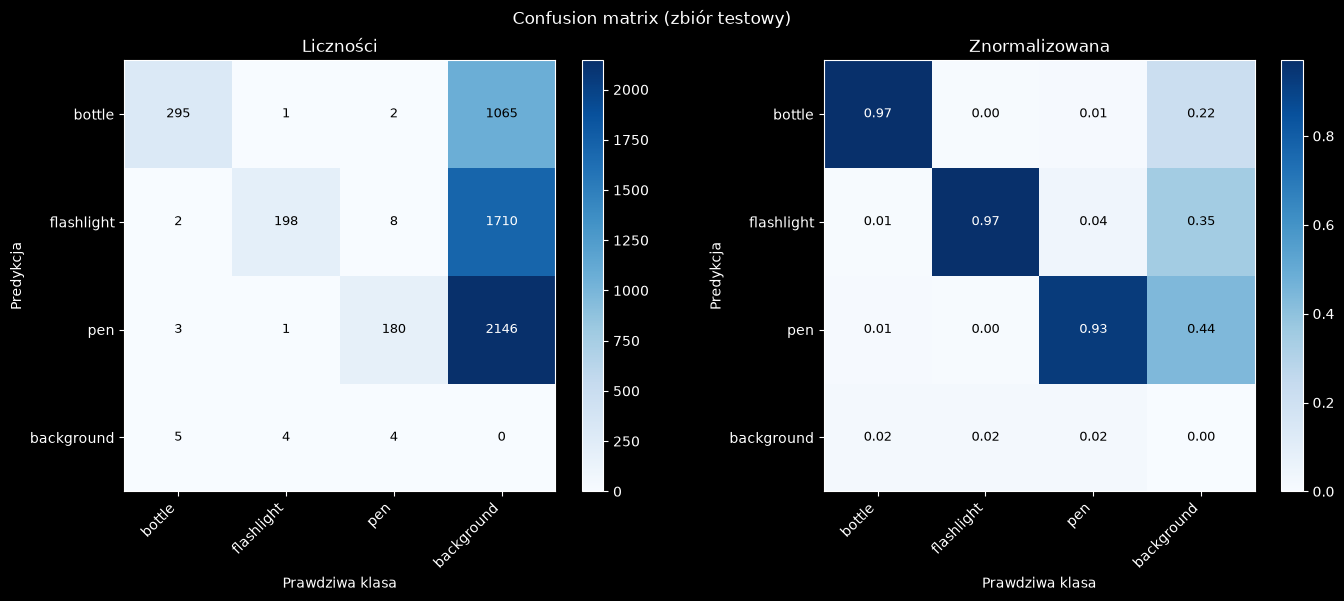

In [8]:
cm = metrics.confusion_matrix.matrix
labels = list(model.names.values()) + ["background"]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, normalize in zip(axes, [False, True]):
    data = cm / cm.sum(axis=0, keepdims=True).clip(min=1) if normalize else cm
    im = ax.imshow(data, cmap="Blues")
    fig.colorbar(im, ax=ax, fraction=0.046)
    ax.set_xticks(range(len(labels)), labels, rotation=45, ha="right")
    ax.set_yticks(range(len(labels)), labels)
    ax.set_xlabel("Prawdziwa klasa")
    ax.set_ylabel("Predykcja")
    ax.set_title("Znormalizowana" if normalize else "Liczności")
    for i in range(len(labels)):
        for j in range(len(labels)):
            val = data[i, j]
            text = f"{val:.2f}" if normalize else f"{int(val)}"
            ax.text(j, i, text, ha="center", va="center",
                    color="white" if val > data.max() / 2 else "black", fontsize=9)

plt.suptitle("Confusion matrix (zbiór testowy)")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=120)
plt.show()

## 4. Predykcja na przykładowych obrazach

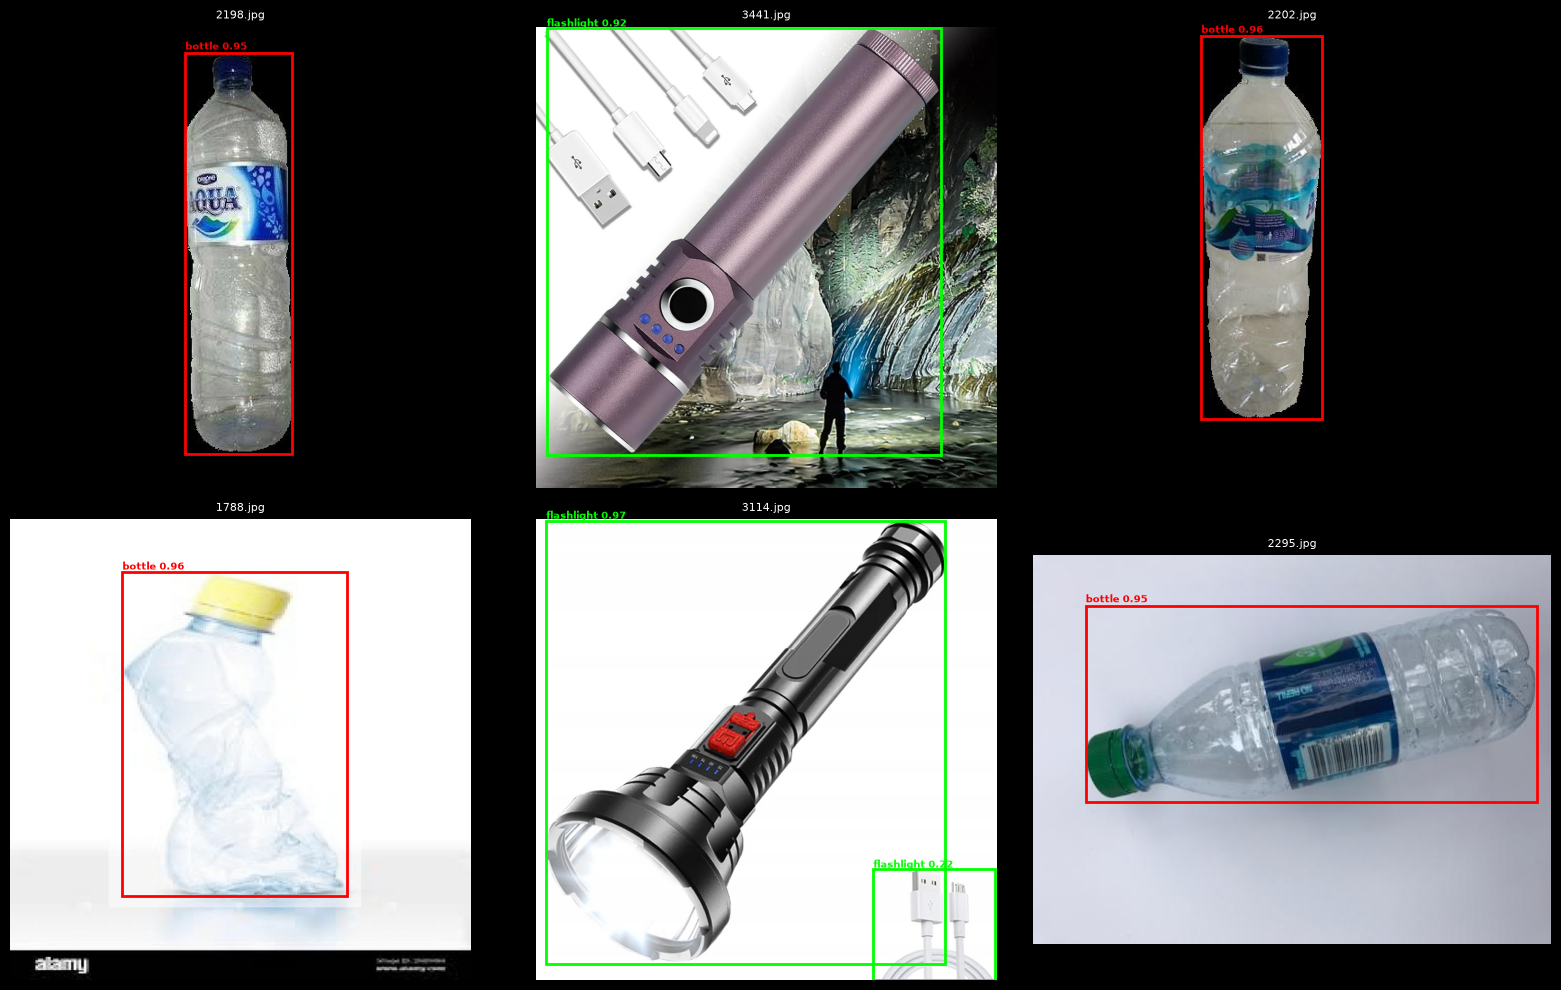

In [5]:
test_imgs = sorted(Path("dataset/images/test").glob("*.jpg"))
sample_paths = random.sample(test_imgs, k=min(6, len(test_imgs)))

COLORS = {"bottle": "red", "flashlight": "lime", "pen": "cyan"}

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

preds = model.predict(sample_paths, imgsz=256, conf=0.2, device=DEVICE, verbose=False)

for ax, res in zip(axes, preds):
    img = Image.fromarray(res.orig_img[..., ::-1])
    ax.imshow(img)
    ax.set_title(Path(res.path).name, fontsize=8)
    ax.axis("off")
    if res.boxes is not None:
        for box, cls, score in zip(res.boxes.xyxy.cpu(), res.boxes.cls.cpu().int(), res.boxes.conf.cpu()):
            x1, y1, x2, y2 = box.tolist()
            cls_name = res.names[int(cls)]
            color = COLORS.get(cls_name, "white")
            rect = patches.Rectangle((x1, y1), x2 - x1, y2 - y1,
                                      linewidth=2, edgecolor=color, facecolor="none")
            ax.add_patch(rect)
            ax.text(x1, y1 - 4, f"{cls_name} {score:.2f}",
                    color=color, fontsize=7, fontweight="bold")

plt.tight_layout()
plt.savefig("predictions.png", dpi=120)
plt.show()

## 5. Zapis modelu

In [6]:
shutil.copy(best_weights, "best.pt")
print(f"Model zapisany jako best.pt (z {best_weights.relative_to(Path.cwd(), walk_up=True)})")

Model zapisany jako best.pt (z runs/detect/runs/yolo26n-3/weights/best.pt)


# 6. Cleanup

In [7]:
shutil.rmtree("runs", ignore_errors=True)
print("Usunięto folder runs/")

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    print("Wyczyszczono pamięć GPU")


Usunięto folder runs/
Wyczyszczono pamięć GPU
